# Isolation Forest

## 1. Cấu hình

In [1]:
%load_ext autoreload
%autoreload 2
import json, time, warnings
from pathlib import Path
import joblib
import sys
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "module").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from module.ml_utils import load_data, split_time, split_stratified, run_eval, plot_eval

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

DATA_PATH = "D:\DACN\dataset\creditcard.csv"   
SPLIT = "time"                 
SEED = 42
DROP_DUPLICATES = True
MODEL_TAG = "isolation_forest"            
OUT_DIR = PROJECT_ROOT / "results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Đọc dữ liệu và chia train / validation / test

In [2]:

df = load_data(DATA_PATH, DROP_DUPLICATES)
# Bỏ 'Time' khỏi đặc trưng: chỉ là số giây kể từ giao dịch đầu tiên, không tổng quát hóa được.
features = [c for c in df.columns if c not in ("Time", "Class")]

train, val, test = split_time(df) if SPLIT == "time" else split_stratified(df, SEED)
data_info = {name: {"rows": len(p), "fraud": int(p["Class"].sum()),
                    "fraud_pct": round(float(p["Class"].mean() * 100), 4)}
             for name, p in [("train", train), ("val", val), ("test", test)]}
display(pd.DataFrame(data_info).T)
assert all(v["fraud"] > 0 for v in data_info.values()), \
    "Có tập không chứa mẫu fraud -> đổi SPLIT = 'stratified'"

Đọc 284,807 dòng -> 283,726 dòng sau khi bỏ trùng | fraud = 473 (0.167%)


,rows,fraud,fraud_pct
train,170235.0,342.0,0.2009
val,56745.0,57.0,0.1004
test,56746.0,74.0,0.1304


## 3. Mô hình: Isolation Forest

In [3]:
PARAMS = dict(n_estimators=300, max_samples=256, contamination="auto", n_jobs=-1)
FIT_ON_LEGIT_ONLY = False   # True: chỉ fit trên giao dịch hợp lệ (thử nghiệm bổ sung, có dùng nhãn để lọc)

from sklearn.ensemble import IsolationForest


def train_fn(X_tr, y_tr, X_va, y_va, seed):
    model = IsolationForest(random_state=seed, **PARAMS)
    X_fit = X_tr[y_tr == 0] if FIT_ON_LEGIT_ONLY else X_tr           # mặc định: không dùng nhãn
    t0 = time.perf_counter()
    model.fit(X_fit)
    train_time = time.perf_counter() - t0
    return model, (lambda X: -model.score_samples(X)), train_time    # điểm càng cao càng bất thường

## 4. Huấn luyện, chọn ngưỡng trên validation, đánh giá trên test

In [4]:
metrics, art = run_eval(train_fn, train, val, test, features, SEED)
display(pd.Series(metrics, name=MODEL_TAG).to_frame())

,isolation_forest
threshold,0.594044
precision,0.043360
recall,0.216216
f1,0.072235
roc_auc,0.944459
pr_auc,0.033297
tp,16.000000
fp,353.000000
fn,58.000000
tn,56319.000000


## 5. Biểu đồ

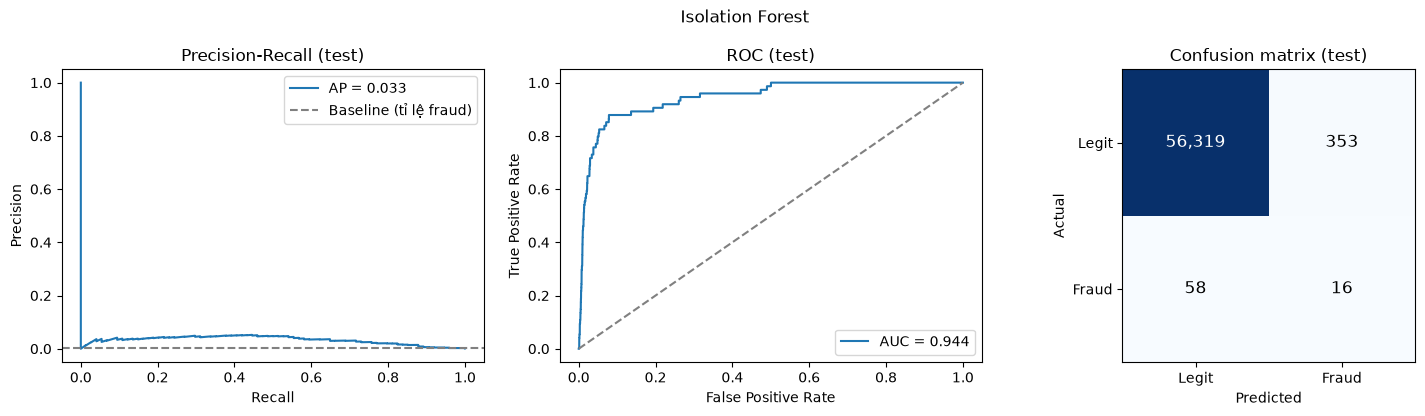

In [5]:
plot_eval(art, "Isolation Forest", OUT_DIR / f"{MODEL_TAG}_eval.png")

### Phân bố điểm bất thường

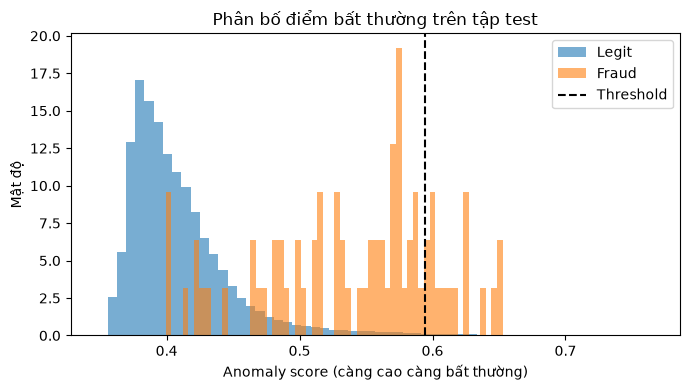

In [6]:
y, s, thr = art["y_te"], art["s_te"], art["thr"]
plt.figure(figsize=(7, 4))
plt.hist(s[y == 0], bins=60, alpha=0.6, density=True, label="Legit")
plt.hist(s[y == 1], bins=60, alpha=0.6, density=True, label="Fraud")
plt.axvline(thr, c="k", ls="--", label="Threshold")
plt.xlabel("Anomaly score (càng cao càng bất thường)")
plt.ylabel("Mật độ")
plt.title("Phân bố điểm bất thường trên tập test")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / f"{MODEL_TAG}_score_distribution.png", dpi=150)
plt.show()

## 6. Lưu kết quả và in số liệu để ghi báo cáo

In [7]:
report = {
    "model": MODEL_TAG, "split": SPLIT, "seed": SEED, "drop_duplicates": DROP_DUPLICATES,
    "params": PARAMS, "data": data_info, "metrics": metrics,
}
(OUT_DIR / f"{MODEL_TAG}_metrics.json").write_text(
    json.dumps(report, indent=2, ensure_ascii=False, default=float))
joblib.dump({"model": art["model"], "threshold": art["thr"], "features": features},
            OUT_DIR / f"{MODEL_TAG}.joblib")

m = metrics
print("=== SỐ LIỆU GHI VÀO BÁO CÁO (tập test) ===")
print(f"Precision          : {m['precision']:.4f}")
print(f"Recall             : {m['recall']:.4f}")
print(f"F1-score           : {m['f1']:.4f}")
print(f"ROC-AUC            : {m['roc_auc']:.4f}")
print(f"PR-AUC             : {m['pr_auc']:.4f}")
print(f"Confusion matrix   : TN={m['tn']:,}  FP={m['fp']:,}  FN={m['fn']:,}  TP={m['tp']:,}")
print(f"Threshold          : {m['threshold']:.6f}")
print(f"Thời gian train    : {m['train_time_s']:.2f} s")
print(f"Suy luận (batch)   : {m['infer_ms_per_1k']:.2f} ms / 1000 giao dịch")
print(f"Suy luận (từng GD) : {m['latency_ms_single']:.2f} ms / giao dịch")
print(f"\nĐã lưu vào: {OUT_DIR.resolve()}")

=== SỐ LIỆU GHI VÀO BÁO CÁO (tập test) ===
Precision          : 0.0434
Recall             : 0.2162
F1-score           : 0.0722
ROC-AUC            : 0.9445
PR-AUC             : 0.0333
Confusion matrix   : TN=56,319  FP=353  FN=58  TP=16
Threshold          : 0.594044
Thời gian train    : 0.93 s
Suy luận (batch)   : 13.87 ms / 1000 giao dịch
Suy luận (từng GD) : 21.21 ms / giao dịch

Đã lưu vào: D:\DACN\results


## 7. (Tùy chọn) Chạy lặp nhiều seed để có mean ± std

Tập fraud rất nhỏ nên một lần chia có thể dao động mạnh. Ô này dùng chia ngẫu nhiên có phân tầng với nhiều seed.

In [8]:
RUN_MULTI_SEED = True   # đổi thành True để chạy lặp (mất thời gian hơn)
N_SEEDS = 5

if RUN_MULTI_SEED:
    rows = []
    for s in range(SEED, SEED + N_SEEDS):
        tr, va, te = split_stratified(df, s)      # lặp nhiều seed chỉ có ý nghĩa với chia ngẫu nhiên
        mt, _ = run_eval(train_fn, tr, va, te, features, s)
        rows.append({"seed": s, **mt})
        print(f"seed {s}: F1={mt['f1']:.3f}  PR-AUC={mt['pr_auc']:.3f}")
    multi = pd.DataFrame(rows)
    cols = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
    display(multi[cols].agg(["mean", "std"]).round(4))
    multi.to_csv(OUT_DIR / f"{MODEL_TAG}_multi_seed.csv", index=False)

seed 42: F1=0.234  PR-AUC=0.109
seed 43: F1=0.278  PR-AUC=0.148
seed 44: F1=0.216  PR-AUC=0.134
seed 45: F1=0.211  PR-AUC=0.122
seed 46: F1=0.321  PR-AUC=0.246


,precision,recall,f1,roc_auc,pr_auc
mean,0.2615,0.2463,0.2518,0.9478,0.1517
std,0.0432,0.0579,0.0470,0.0081,0.0545
